In [1]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Movie-Data.csv")

df = df.drop_duplicates()

for col in ["Revenue (Millions)", "Rating", "Year"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

genre_df = df.dropna(subset=["Genre"]).copy()
genre_df["Genre"] = genre_df["Genre"].str.split(",")
genre_df = genre_df.explode("Genre")
genre_df["Genre"] = genre_df["Genre"].str.strip()

## 1. Which movie genres generate the highest average revenue?

Statement :- Animation movies generate the highest average revenue at 191.22 million, while horror movies have the lowest average revenue at 36.71 million.


1. Average Revenue by Genre
Genre
Animation    191.22
Adventure    154.18
Sci-Fi       135.55
Fantasy      131.85
Family       126.18
Action       124.49
Western      111.82
Musical       81.64
Comedy        75.75
Thriller      69.58
Sport         65.04
Crime         61.80
Biography     55.80
Mystery       54.63
War           53.43
History       52.92
Drama         49.84
Music         47.07
Romance       42.50
Horror        36.71
Name: Revenue (Millions), dtype: float64


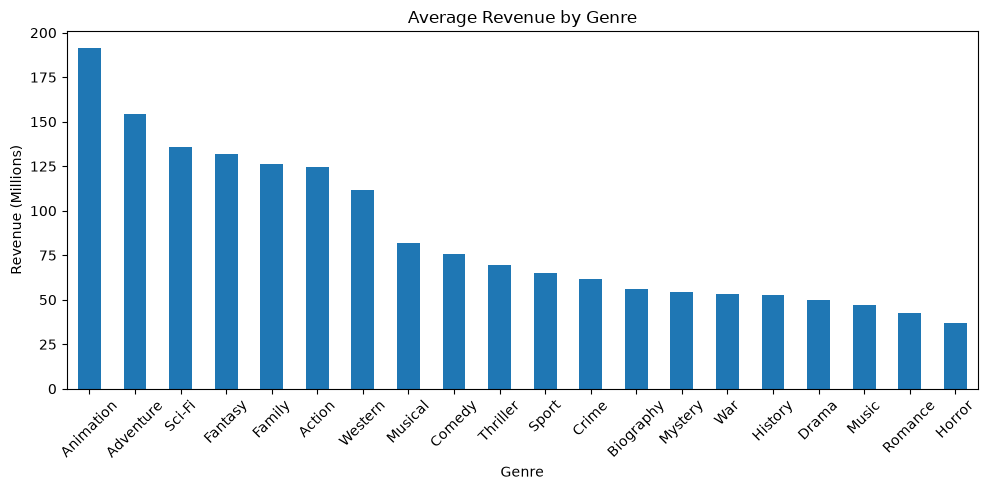

In [2]:
genre_revenue = (
    genre_df.dropna(subset=["Revenue (Millions)"])
    .groupby("Genre")["Revenue (Millions)"]
    .mean()
    .sort_values(ascending=False)
)

print("\n1. Average Revenue by Genre")
print(genre_revenue.round(2))

genre_revenue.plot(kind="bar", figsize=(10, 5))
plt.title("Average Revenue by Genre")
plt.xlabel("Genre")
plt.ylabel("Revenue (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Is there a correlation between a movie’s budget and its revenue?

Statement :- A budget and profit analysis could not be performed because the dataset does not contain a Budget column.



In [3]:
if "Budget" in df.columns:
    data = df[["Budget", "Revenue (Millions)"]].dropna()
    print("\n2. Budget-Revenue Correlation:")
    print(data["Budget"].corr(data["Revenue (Millions)"]))

    data.plot(
        kind="scatter",
        x="Budget",
        y="Revenue (Millions)",
        figsize=(8, 5)
    )
    plt.title("Budget vs Revenue")
    plt.tight_layout()
    plt.show()
else:
    print("\n2. Budget analysis not possible:")
    print("The dataset does not contain a Budget column.")


2. Budget analysis not possible:
The dataset does not contain a Budget column.


## 3. Which movies were the most profitable (Revenue – Budget)?

Statement :- Episode VII - The Force Awakens is the highest-grossing movie in the dataset with a revenue of 936.63 million.



3. Profit analysis not possible without Budget.
Showing the 10 highest-grossing movies instead.
                                          Title  Revenue (Millions)
50   Star Wars: Episode VII - The Force Awakens              936.63
87                                       Avatar              760.51
85                               Jurassic World              652.18
76                                 The Avengers              623.28
54                              The Dark Knight              533.32
12                                    Rogue One              532.17
119                                Finding Dory              486.29
94                      Avengers: Age of Ultron              458.99
124                       The Dark Knight Rises              448.13
578             The Hunger Games: Catching Fire              424.65


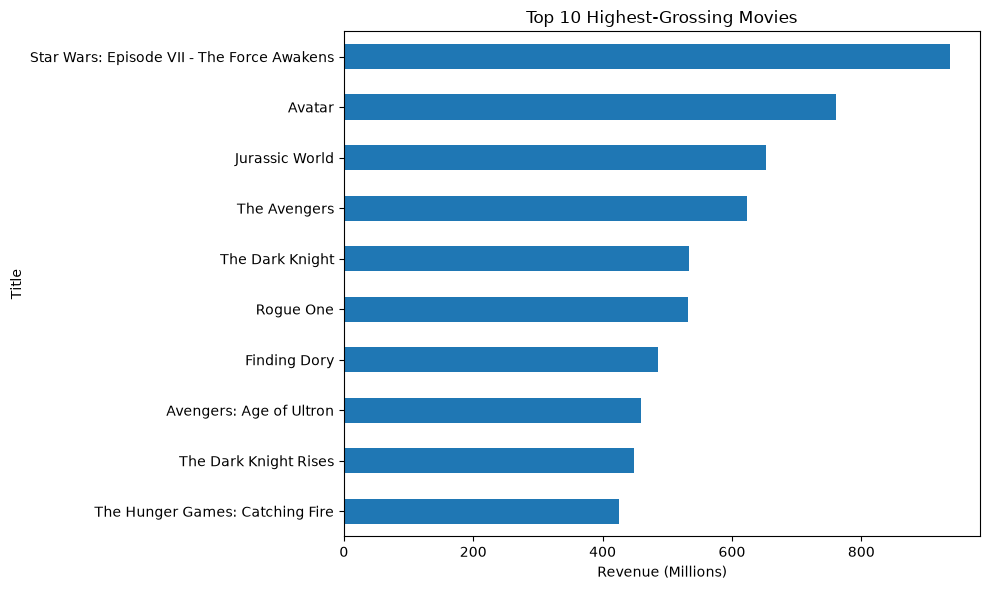

In [4]:
if "Budget" in df.columns:
    df["Profit"] = df["Revenue (Millions)"] - df["Budget"]
    top_profit = df.nlargest(10, "Profit")

    print("\n3. Top 10 Most Profitable Movies")
    print(top_profit[["Title", "Profit"]])

    top_profit.plot(
        x="Title", y="Profit", kind="barh", figsize=(10, 6)
    )
    plt.title("Top 10 Most Profitable Movies")
    plt.tight_layout()
    plt.show()
else:
    print("\n3. Profit analysis not possible without Budget.")
    print("Showing the 10 highest-grossing movies instead.")

    top_revenue = df.nlargest(10, "Revenue (Millions)")
    print(top_revenue[["Title", "Revenue (Millions)"]])

    top_revenue.plot(
        x="Title",
        y="Revenue (Millions)",
        kind="barh",
        figsize=(10, 6),
        legend=False
    )
    plt.title("Top 10 Highest-Grossing Movies")
    plt.xlabel("Revenue (Millions)")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()


## 4. Do movies with higher ratings earn more at the box office?

Statement :- Episode VII - The Force Awakens is the highest-grossing movie in the dataset with a revenue of 936.63 million.


4. Rating-Revenue Correlation: 0.218


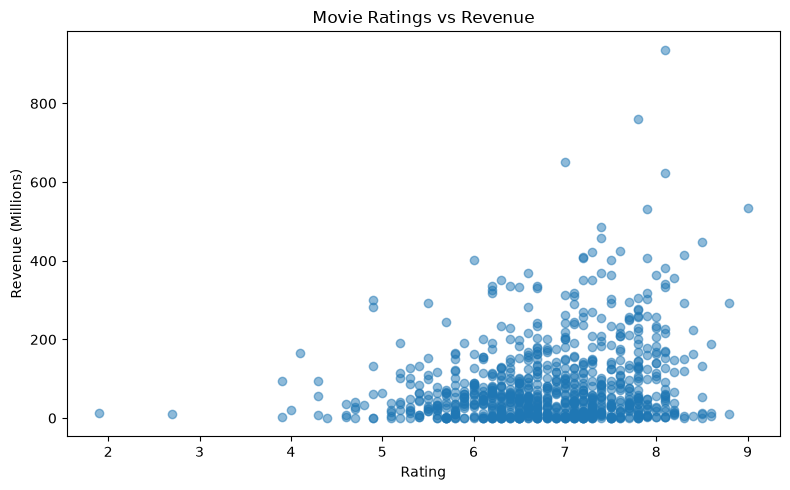

In [5]:
rating_data = df[["Rating", "Revenue (Millions)"]].dropna()

correlation = rating_data["Rating"].corr(
    rating_data["Revenue (Millions)"]
)

print("\n4. Rating-Revenue Correlation:", round(correlation, 3))

plt.figure(figsize=(8, 5))
plt.scatter(
    rating_data["Rating"],
    rating_data["Revenue (Millions)"],
    alpha=0.5
)
plt.title("Movie Ratings vs Revenue")
plt.xlabel("Rating")
plt.ylabel("Revenue (Millions)")
plt.tight_layout()
plt.show()

## 5. Which directors consistently produce high-rated movies?

Statement :- Nolan leads the directors with the highest average rating of 8.68 across 5 movies.



5. Top Directors by Average Rating
                             Average_Rating  Movie_Count
Director                                                
Christopher Nolan                      8.68            5
Martin Scorsese                        7.92            5
Quentin Tarantino                      7.90            4
Wes Anderson                           7.90            3
David Fincher                          7.82            5
Alejandro González Iñárritu            7.77            3
Denis Villeneuve                       7.76            5
Matthew Vaughn                         7.72            4
Clint Eastwood                         7.70            4
Steve McQueen                          7.63            3


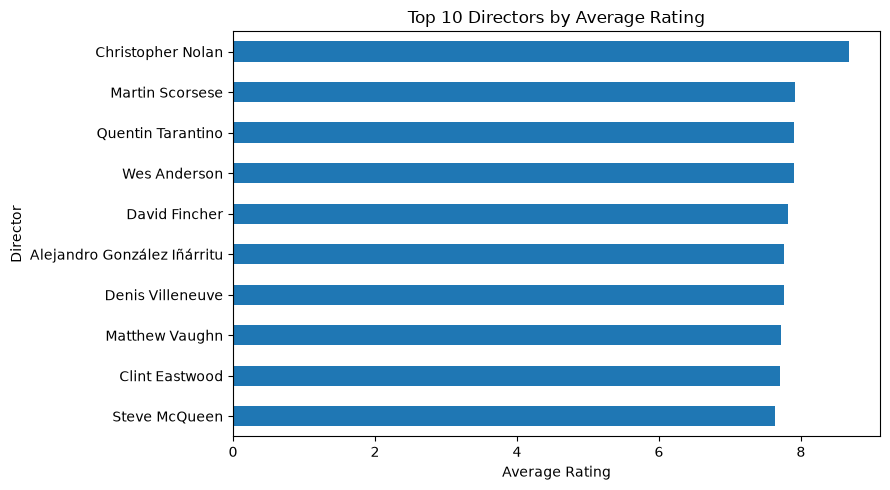

In [6]:
director_ratings = (
    df.dropna(subset=["Director", "Rating"])
    .groupby("Director")
    .agg(
        Average_Rating=("Rating", "mean"),
        Movie_Count=("Rating", "count")
    )
)

director_ratings = director_ratings[
    director_ratings["Movie_Count"] >= 3
]

top_directors = director_ratings.sort_values(
    "Average_Rating", ascending=False
).head(10)

print("\n5. Top Directors by Average Rating")
print(top_directors.round(2))

top_directors["Average_Rating"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Top 10 Directors by Average Rating")
plt.xlabel("Average Rating")
plt.tight_layout()
plt.show()

## 6. How has the number of movies released per year changed over time?

Statement :- The number of recorded movie releases per year grew substantially, rising from 44 movies in 2006 to 297 movies in 2016


6. Movies Released Per Year
Year
2006     44
2007     53
2008     52
2009     51
2010     60
2011     63
2012     64
2013     91
2014     98
2015    127
2016    297
dtype: int64


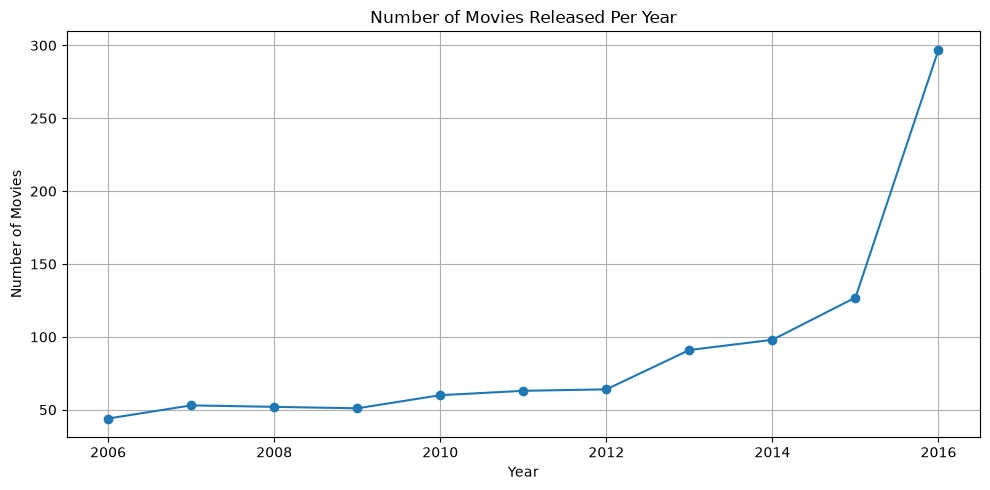

In [7]:
yearly_movies = df.dropna(subset=["Year"]).groupby("Year").size()

print("\n6. Movies Released Per Year")
print(yearly_movies)

yearly_movies.plot(
    kind="line", marker="o", figsize=(10, 5)
)
plt.title("Number of Movies Released Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.grid(True)
plt.tight_layout()
plt.show()


## 7. Which genre is trending recently (highest growth in number of releases)?

Statement :- Based on the growth in the number of releases between 2012 and 2016, Drama experienced the highest increase in releases (jumping from 28 to 162 movies), followed significantly by Action (from 21 to 75 movies) and Comedy (from 21 to 83 movies).


7. Genre Releases by Year
col_0  Action  Adventure  Animation  Biography  Comedy  Crime  Drama  Family  \
row_0                                                                          
2012       21         18          2          2      21      9     28       1   
2013       29         22          3         10      23     19     44       2   
2014       37         30          4          6      30     14     50       4   
2015       35         33          4         12      37     21     74       8   
2016       75         62         18         31      83     41    162      12   

col_0  Fantasy  History  Horror  Music  Musical  Mystery  Romance  Sci-Fi  \
row_0                                                                       
2012         7        3       5      1        2        5       11       8   
2013        11        1      13      1        0       13       13      16   
2014         7        1       8      2        0       13       18      17   
2015         7        5    

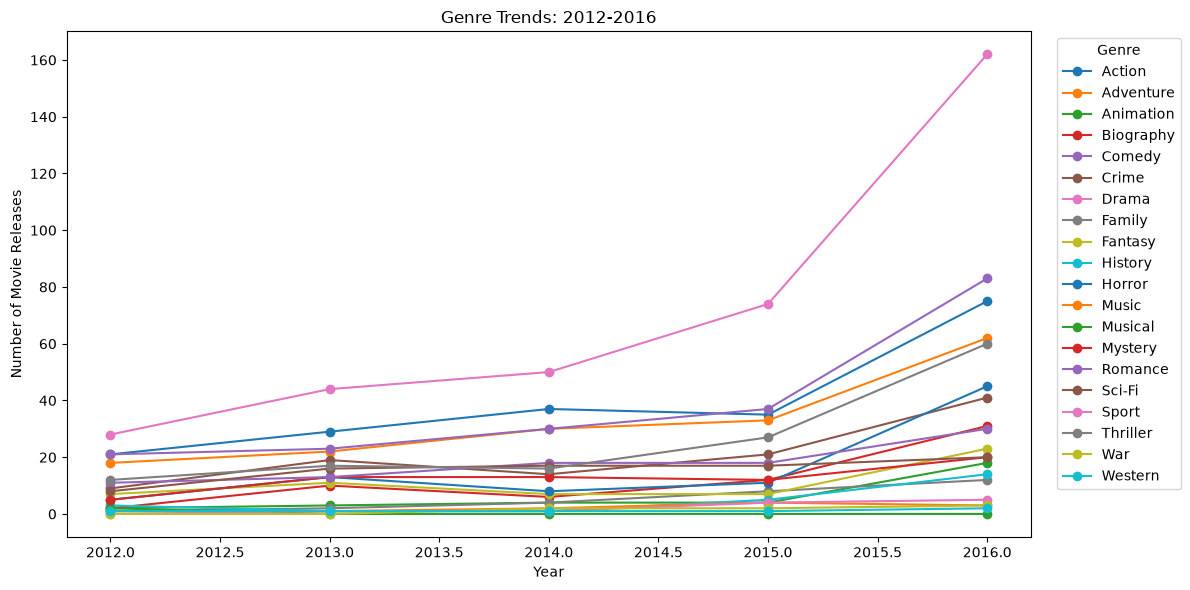


Genres with Highest Increase in Releases
col_0
Drama        134
Comedy        62
Action        54
Thriller      48
Adventure     44
Horror        40
Crime         32
Biography     29
Romance       19
Animation     16
dtype: int64


In [9]:

genre_df = genre_df.loc[:, ~genre_df.columns.duplicated()].copy()

genre_df = genre_df.reset_index(drop=True)

valid_genres = genre_df.dropna(
    subset=["Year", "Title", "Genre"]
).copy()

valid_genres["Year"] = pd.to_numeric(
    valid_genres["Year"], errors="coerce"
)

valid_genres = valid_genres.dropna(subset=["Year"])
valid_genres["Year"] = valid_genres["Year"].astype(int)

latest_year = valid_genres["Year"].max()
start_year = latest_year - 4

recent = valid_genres[
    valid_genres["Year"].between(start_year, latest_year)
].copy().reset_index(drop=True)

genre_trend = pd.crosstab(
    recent["Year"].to_numpy(),
    recent["Genre"].to_numpy()
)

genre_trend = genre_trend.reindex(
    range(start_year, latest_year + 1),
    fill_value=0
)

print("\n7. Genre Releases by Year")
print(genre_trend)

genre_trend.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title(f"Genre Trends: {start_year}-{latest_year}")
plt.xlabel("Year")
plt.ylabel("Number of Movie Releases")
plt.legend(
    title="Genre",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

if len(genre_trend) >= 2:
    growth = (
        genre_trend.iloc[-1] - genre_trend.iloc[0]
    ).sort_values(ascending=False)

    print("\nGenres with Highest Increase in Releases")
    print(growth.head(10))
